In [1]:
#202431055_Muhammad Rafi Kurniawan
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
#202431055_Muhammad Rafi Kurniawan
CSV_FILE = "populasi_un_clean.csv"

if not os.path.exists(CSV_FILE):
    from google.colab import files
    files.upload()

df = pd.read_csv(CSV_FILE)
print("Ukuran data:", df.shape)
display(df.head())
print()
df.info()

Ukuran data: (237, 6)


,negara,populasi_2022,populasi_2023,perubahan_persen,benua,subregion
0,India,1.425423e+09,1.438070e+09,0.89,Asia,Southern Asia
1,China,1.425180e+09,1.422585e+09,-0.18,Asia,Eastern Asia
2,United States,3.415340e+08,3.434773e+08,0.57,Americas,Northern America
3,Indonesia,2.788305e+08,2.811901e+08,0.85,Asia,South-eastern Asia
4,Pakistan,2.437007e+08,2.475045e+08,1.56,Asia,Southern Asia



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 237 entries, 0 to 236
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   negara            237 non-null    object 
 1   populasi_2022     237 non-null    float64
 2   populasi_2023     237 non-null    float64
 3   perubahan_persen  237 non-null    float64
 4   benua             237 non-null    object 
 5   subregion         237 non-null    object 
dtypes: float64(3), object(3)
memory usage: 11.2+ KB


In [3]:
#202431055_Muhammad Rafi Kurniawan
kolom_x = ["populasi_2022", "perubahan_persen"]
kolom_y = "populasi_2023"

print("Jumlah data sebelum dropna:", len(df))
print("Data kosong per kolom:")
print(df[kolom_x + [kolom_y]].isna().sum())

df = df.dropna(subset=kolom_x + [kolom_y])
print("\nJumlah data sesudah dropna:", len(df))

Jumlah data sebelum dropna: 237
Data kosong per kolom:
populasi_2022       0
perubahan_persen    0
populasi_2023       0
dtype: int64

Jumlah data sesudah dropna: 237


In [4]:
#202431055_Muhammad Rafi Kurniawan
df["populasi_2022_juta"] = df["populasi_2022"] / 1_000_000
df["populasi_2023_juta"] = df["populasi_2023"] / 1_000_000

kolom_x = ["populasi_2022_juta", "perubahan_persen"]
kolom_y = "populasi_2023_juta"

X = df[kolom_x]
y = df[kolom_y]

print("Bentuk X:", X.shape, "| Bentuk y:", y.shape)

# Gambaran awal hubungan fitur dengan target
print("\nKorelasi dengan target:")
print(df[kolom_x + [kolom_y]].corr()[kolom_y].round(4))

Bentuk X: (237, 2) | Bentuk y: (237,)

Korelasi dengan target:
populasi_2022_juta    1.0000
perubahan_persen     -0.0206
populasi_2023_juta    1.0000
Name: populasi_2023_juta, dtype: float64


In [5]:
#202431055_Muhammad Rafi Kurniawan
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)
print("Data latih:", X_train.shape[0], "baris")
print("Data uji  :", X_test.shape[0], "baris")

Data latih: 189 baris
Data uji  : 48 baris


In [6]:
#202431055_Muhammad Rafi Kurniawan
model = LinearRegression()
print(model)

LinearRegression()


In [7]:
#202431055_Muhammad Rafi Kurniawan
model.fit(X_train, y_train)
print("Model selesai dilatih.")

Model selesai dilatih.


In [8]:
#202431055_Muhammad Rafi Kurniawan
y_pred = model.predict(X_test)

hasil = pd.DataFrame({
    "negara": df.loc[X_test.index, "negara"] if "negara" in df.columns else X_test.index,
    "aktual_juta": y_test.values.round(3),
    "prediksi_juta": y_pred.round(3),
})
hasil["selisih_juta"] = (hasil["aktual_juta"] - hasil["prediksi_juta"]).round(3)
display(hasil.head(10))

,negara,aktual_juta,prediksi_juta,selisih_juta
173,Maldives,0.526,0.558,-0.032
152,Kosovo,1.700,1.480,0.220
106,Kyrgyzstan,7.074,7.278,-0.204
111,El Salvador,6.310,6.359,-0.049
125,Oman,5.049,6.041,-0.992
224,Anguilla(United Kingdom),0.014,0.295,-0.281
122,New Zealand,5.173,5.271,-0.098
179,Guadeloupe(France),0.377,-0.074,0.451
45,Ghana,33.788,33.622,0.166
203,Andorra,0.081,0.325,-0.244


In [9]:
#202431055_Muhammad Rafi Kurniawan
koefisien = model.coef_
intercept = model.intercept_
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)

print("Koefisien :")
for nama, b in zip(kolom_x, koefisien):
    print(f"   {nama:18s}: {b:,.6f}")
print(f"Intercept : {intercept:,.6f}")
print(f"MSE       : {mse:,.6f} (juta jiwa)^2")
print(f"RMSE      : {rmse:,.6f} juta jiwa  (= {rmse*1_000_000:,.0f} jiwa)")
print(f"R2 Score  : {r2:.6f}")
print(f"\nR2 data latih: {model.score(X_train, y_train):.6f} (pembanding untuk cek overfitting)")

Koefisien :
   populasi_2022_juta: 1.003960
   perubahan_persen  : 0.197475
Intercept : -0.039263
MSE       : 0.360842 (juta jiwa)^2
RMSE      : 0.600701 juta jiwa  (= 600,701 jiwa)
R2 Score  : 0.999847

R2 data latih: 0.999965 (pembanding untuk cek overfitting)


In [10]:
#202431055_Muhammad Rafi Kurniawan
a  = intercept
b1, b2 = koefisien

print("Persamaan regresi:")
print(f"populasi_2023 (juta) = {a:.6f} + ({b1:.6f} x populasi_2022 (juta)) + ({b2:.6f} x perubahan_persen)")
print("\nBentuk simbolik:  Y = a + b1.x1 + b2.x2")
print(f"   a  = {a:.6f}")
print(f"   b1 = {b1:.6f}")
print(f"   b2 = {b2:.6f}")

contoh = pd.DataFrame([[10.0, 1.5]], columns=kolom_x)
print(f"\nContoh prediksi populasi 2023 (10 juta, +1,5%): {model.predict(contoh)[0]:.4f} juta jiwa")

Persamaan regresi:
populasi_2023 (juta) = -0.039263 + (1.003960 x populasi_2022 (juta)) + (0.197475 x perubahan_persen)

Bentuk simbolik:  Y = a + b1.x1 + b2.x2
   a  = -0.039263
   b1 = 1.003960
   b2 = 0.197475

Contoh prediksi populasi 2023 (10 juta, +1,5%): 10.2966 juta jiwa


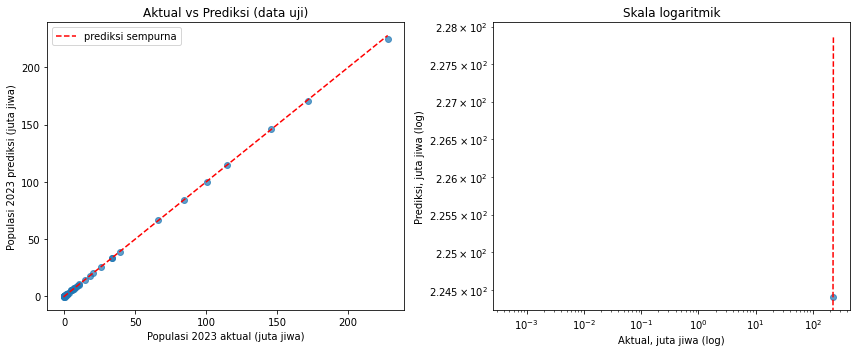

In [11]:
#202431055_Muhammad Rafi Kurniawan
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# (a) aktual vs prediksi: titik di sekitar garis merah = prediksi akurat
ax[0].scatter(y_test, y_pred, alpha=0.7)
lim = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax[0].plot(lim, lim, "r--", label="prediksi sempurna")
ax[0].set_xlabel("Populasi 2023 aktual (juta jiwa)")
ax[0].set_ylabel("Populasi 2023 prediksi (juta jiwa)")
ax[0].set_title("Aktual vs Prediksi (data uji)")
ax[0].legend()

# (b) skala log agar negara kecil juga terlihat
ax[1].scatter(y_test, y_pred, alpha=0.7)
ax[1].plot(lim, lim, "r--")
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("Aktual, juta jiwa (log)"); ax[1].set_ylabel("Prediksi, juta jiwa (log)")
ax[1].set_title("Skala logaritmik")

plt.tight_layout()
plt.show()